## Netowork physiology

In [ ]:
'''
Python notebook for the construction and analysis of a knowledge-based physiological network, based on the principles of endobiogeny.
Using the networkx library, it builds a directed signed graph where nodes represent hormones/organs and edges represent regulatory interactions
(+1 = stimulation, -1 = inhibition). Structural analysis includes the identification of key nodes via centrality metrics (in-degree, out-degree,
betweenness centrality) and the detection of functional modules using the Louvain community detection algorithm. Outputs consist of ranked lists of critical nodes
(top regulators, bridges) and a graph visualization colored by community structure, revealing the system's modular organization.
The framework is designed to be extended into a multilayered network and eventually into a dynamic network.

'''

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
G = nx.DiGraph()

#### Nodes definition

In [ ]:
# nodes_horm = ['CRH', 'ACTH', 'GnRH', 'FSH', 'LH', 'TRH', 'TSH', 'T3', 'T4', 'GHRH',
#          'GH', 'PL','cortisol', 'estrogens', 'glucagon', 'insulin', 'somatostatin',
#          'progesterone', 'aldosterone', 'DHEA', 'serotonin', 'histamine', 'noradrenaline',
#          'dopamine', 'adrenaline', 'acetylcholine', 'glucose', 'calcitonin', 'melatonin',
#          'oxytocin', 'B-MSH', 'POMC', 'A-MSH', 'carbohydrates', 'lipids', 'proteins',
#          'b-endorphin', 'y-lipotropin', 'enkephalins', 'glutamate', 'calcium', 'potasium',
#          'vasopressin', 'ANP', 'angiotensin', 'prostaglandin e', 'inhibin', 'activin', 'leptin',
#          'estradiol', 'estriol', 'estrone', 'testosterone', 'DHT', 'PTH', 'vitamin d', 'IGF-1',
#          'ghrelin', 'CCK', 'urea', 'FFA', 'IGF-2', 'IGF-BP3'
#          ]

In [ ]:
# nodes_sys = ['cortex subcortex', 'CNS', 'brain stem', 'spinal cord', 'locus ceruleus',
#              'cranial nerves', 'somatic nerves', 'visceral nerves', 'ENS', 'adrenal medulla',
#              'ANS', 'parasympathetic', 'alpha sympathetic', 'beta sympathetic', 'hypothalamus',
#              'limbic area', 'liver', 'pancreas', 'thyroid gland', 'adrenal cortex', 'pituitary',
#              'GI tract', 'kidney', 'bone', 'thymus', 'lung', 'skin'
#              ]

In [ ]:
# nodes_comp = ['CRH', 'ACTH', 'GnRH', 'FSH', 'LH', 'TRH', 'TSH', 'T3', 'T4', 'GHRH',
#          'GH', 'PL','cortisol', 'estrogens', 'glucagon', 'insulin', 'somatostatin',
#          'progesterone', 'aldosterone', 'DHEA', 'serotonin', 'histamine', 'noradrenaline',
#          'dopamine', 'adrenaline', 'acetylcholine', 'glucose', 'calcitonin', 'melatonin',
#          'oxytocin', 'B-MSH', 'POMC', 'A-MSH', 'carbohydrates', 'lipids', 'proteins',
#          'b-endorphin', 'y-lipotropin', 'enkephalins', 'glutamate', 'calcium', 'potasium',
#          'vasopressin', 'ANP', 'angiotensin', 'prostaglandin e', 'inhibin', 'activin', 'leptin',
#          'estradiol', 'estriol', 'estrone', 'testosterone', 'DHT', 'PTH', 'vitamin D', 'IGF-1',
#          'ghrelin', 'CCK', 'urea', 'FFA', 'IGF-2', 'IGF-BP3' 'cortex subcortex', 'CNS', 'brain stem',
#           'spinal cord', 'locus ceruleus', 'cranial nerves', 'somatic nerves', 'visceral nerves',
#               'ENS', 'adrenal medulla','ANS', 'parasympathetic', 'alpha sympathetic', 'beta sympathetic',
#               'hypothalamus','limbic area', 'liver', 'pancreas', 'thyroid gland', 'adrenal cortex', 'pituitary',
#           'GI tract', 'kidney', 'bone', 'thymus', 'lung', 'skin'
#           ]

#### Edges definition

In [4]:
edge_list = [
    # ANS and neurotransmitters
    ('alpha sympathetic', 'beta sympathetic', {'sign': -1}),
    ('beta sympathetic', 'para sympathetic', {'sign': -1}),
    ('para sympathetic', 'alpha sympathetic', {'sign': -1}),
    ('ANS', 'alpha sympathetic', {'sign': 1}),
    ('alpha sympathetic', 'noradrenaline', {'sign': 1}),
    ('noradrenaline', 'dopamine', {'sign': -1}),
    ('ANS', 'para sympathetic', {'sign': 1}),
    ('para sympathetic', 'acetylcholine', {'sign': 1}),
    ('acetylcholine', 'serotonin', {'sign': 1}),
    ('para sympathetic', 'serotonin', {'sign': -1}),
    ('ANS', 'beta sympathetic', {'sign': 1}),
    ('beta sympathetic', 'TRH', {'sign': 1}),
    ('beta sympathetic', 'adrenaline', {'sign': 1}),

    # SNC interactions
    ('alpha sympathetic', 'dopamine', {'sign': 1}),
    ('alpha sympathetic', 'hypothalamus', {'sign': 1}),
    ('dopamine', 'hypothalamus', {'sign': -1}),
    ('hypothalamus', 'dopamine', {'sign': 1}),
    ('TRH', 'dopamine', {'sign': 1}),
    ('dopamine', 'TRH', {'sign': -1}),
    ('alpha sympathetic', 'TRH', {'sign': 1}),
    ('serotonin', 'dopamine', {'sign': -1}),
    ('TRH', 'histamine', {'sign': 1}),

    # HPA
    ('alpha sympathetic', 'ACTH', {'sign': 1}),
    ('CRH', 'ACTH', {'sign': 1}),
    ('ACTH', 'adrenal cortex', {'sign': 1}),
    ('TRH', 'TSH', {'sign': 1}),
    ('TSH', 'T4', {'sign': 1}),
    ('TRH', 'pancreas', {'sign': 1}),
    ('liver', 'glucose', {'sign': 1}),
    ('locus ceruleus', 'alpha sympathetic', {'sign': 1}),
    ('beta sympathetic', 'liver', {'sign': 1}),
    ('TRH', 'serotonin', {'sign': 1}),
    ('serotonin', 'TRH', {'sign': -1}),
    ('ACTH', 'FSH', {'sign': -1}),
    ('FSH', 'TSH', {'sign': 1}),
    ('TSH', 'GH', {'sign': 1}),
    ('b-endorphin', 'ACTH', {'sign': -1}),

    # Gonads
    ('GnRH', 'FSH', {'sign': 1}),
    ('GnRH', 'LH', {'sign': 1}),
    ('GHRH', 'GH', {'sign': 1}),
    ('activin', 'GnRH', {'sign': 1}),
    ('leptin', 'GnRH', {'sign': 1}),
    ('TRH', 'GnRH', {'sign': -1}),
    ('endorphins', 'GnRH', {'sign': -1}),
    ('inhibin', 'GnRH', {'sign': -1}),
    ('estrogens', 'GnRH', {'sign': -1}),
    ('inhibin', 'FSH', {'sign': -1}),
    ('cortisol', 'FSH', {'sign': -1}),
    ('activin', 'FSH', {'sign': 1}),
    ('androgens', 'FSH', {'sign': -1}),
    ('aldosterone', 'LH', {'sign': -1}),
    ('cortisol', 'LH', {'sign': -1}),
    ('estrogens', 'LH', {'sign': 1}),
    ('progesterone', 'LH', {'sign': -1}),
    ('prolactin', 'estrogens', {'sign': -1}),
    ('TRH', 'estrogens', {'sign': -1}),
    ('cortisol', 'estrogens', {'sign': -1}),
    ('progesterone', 'estrogens', {'sign': -1}),
    ('LH', 'androgens', {'sign': 1}),
    ('insulin', 'androgens', {'sign': 1}),
    ('cortisol', 'androgens', {'sign': -1}),
    ('estrogens', 'androgens', {'sign': -1}),
    ('progesterone', 'androgens', {'sign': -1}),

    # Cortisol
    ('ACTH', 'cortisol', {'sign': 1}),
    ('cortisol', 'FSH', {'sign': -1}),
    ('endorphins', 'cortisol', {'sign': 1}),
    ('a-MSH', 'cortisol', {'sign': 1}),
    ('b-MSH', 'cortisol', {'sign': 1}),
    ('estrogens', 'cortisol', {'sign': -1}),
    ('cortisol', 'GI tract', {'sign': -1}),
    ('cortisol', 'liver', {'sign': 1}),
    ('cortisol', 'bone', {'sign': -1}),
    ('cortisol', 'kidney', {'sign': 1}),

    # Melatonin
    ('para sympathetic', 'melatonin', {'sign': 1}),
    ('alpha sympathetic', 'melatonin', {'sign': 1}),
    ('ACTH', 'melatonin', {'sign': -1}),
    ('cortisol', 'melatonin', {'sign': -1}),
    ('oxytocin', 'melatonin', {'sign': 1}),
    ('melatonin', 'b-MSH', {'sign': -1}),
    ('melatonin', 'prolactin', {'sign': 1}),

    # POMC
    ('CRH', 'POMC', {'sign': 1}),
    ('POMC', 'ACTH', {'sign': 1}),
    ('POMC', 'b-lipotropin', {'sign': 1}),
    ('b-lipotropin', 'enkephalins', {'sign': 1}),
    ('b-lipotropin', 'b-endorphin', {'sign': 1}),
    ('b-lipotropin', 'y-lipotropin', {'sign': 1}),
    ('y-lipotropin', 'enkephalins', {'sign': 1}),
    ('y-lipotropin', 'b-MSH', {'sign': 1}),
    ('ACTH', 'a-MSH', {'sign': 1}),
    ('a-MSH', 'ACTH', {'sign': -1}),

    # Ions
    ('glutamate', 'calcium', {'sign': 1}),
    ('glutamate', 'potasium', {'sign': 1}),

    # Aldosterone & vasopressin
    ('ACTH', 'aldosterone', {'sign': 1}),
    ('vasopressin', 'ACTH', {'sign': 1}),
    ('prolactin', 'ACTH', {'sign': 1}),
    ('angiotensin', 'vasopressin', {'sign': 1}),
    ('oxytocin', 'vasopressin', {'sign': 1}),
    ('vasopressin', 'oxytocin', {'sign': 1}),
    ('cortisol', 'vasopressin', {'sign': -1}),
    ('ANP', 'vasopressin', {'sign': -1}),
    ('melatonin', 'vasopressin', {'sign': -1}),
    ('vasopressin', 'MSH', {'sign': 1}),
    ('progesterone', 'oxytocin', {'sign': -1}),
    ('estrogens', 'oxytocin', {'sign': 1}),
    ('ACTH', 'DHEA', {'sign': 1}),
    ('estrogens', 'DHEA', {'sign': -1}),
    ('androgens', 'DHEA', {'sign': -1}),
    ('alpha sympathetic', 'aldosterone', {'sign': 1}),
    ('ANP', 'aldosterone', {'sign': -1}),
    ('prostaglandin e', 'aldosterone', {'sign': 1}),
    ('progesterone', 'aldosterone', {'sign': -1}),
    ('endorphins', 'aldosterone', {'sign': -1}),
    ('angiotensin II', 'aldosterone', {'sign': 1}),

    # Thyroid
    ('T4', 'TRH', {'sign': -1}),
    ('T3', 'TRH', {'sign': -1}),
    ('GnRH', 'TRH', {'sign': -1}),
    ('FSH', 'TRH', {'sign': -1}),
    ('TSH', 'TRH', {'sign': -1}),
    ('somatostatin', 'TRH', {'sign': -1}),
    ('dopamine', 'TRH', {'sign': -1}),
    ('beta sympathetic', 'TRH', {'sign': 1}),
    ('somatostatin', 'TSH', {'sign': -1}),
    ('T4', 'TSH', {'sign': -1}),
    ('progesterone', 'TSH', {'sign': -1}),
    ('estrogens', 'TSH', {'sign': 1}),
    ('estrogens', 'T4', {'sign': 1}),
    ('progesterone', 'T4', {'sign': -1}),
    ('progesterone', 'T3', {'sign': -1}),
    ('T4', 'T3', {'sign': 1}),

    # Calcium
    ('calcitonin', 'vitamin d', {'sign': -1}),
    ('vitamin d', 'PTH', {'sign': -1}),
    ('calcium', 'calcitonin', {'sign': 1}),
    ('calcium', 'vitamin d', {'sign': -1}),
    ('calcium', 'PTH', {'sign': -1}),
    ('TRH', 'vitamin d', {'sign': 1}),
    ('prolactin', 'vitamin d', {'sign': 1}),
    ('cortisol', 'vitamin d', {'sign': -1}),
    ('TSH', 'vitamin d', {'sign': 1}),
    ('T4', 'vitamin d', {'sign': 1}),
    ('T3', 'PTH', {'sign': 1}),

    # Thymus
    ('alpha sympathetic', 'thymus', {'sign': -1}),
    ('cortisol', 'thymus', {'sign': -1}),
    ('TSH', 'thymus', {'sign': 1}),
    ('ACTH', 'thymus', {'sign': -1}),

    # Somatotroph
    ('insulin', 'GHRH', {'sign': -1}),
    ('TSH', 'GHRH', {'sign': 1}),
    ('TRH', 'GHRH', {'sign': 1}),
    ('somatostatin', 'GHRH', {'sign': -1}),
    ('prolactin', 'GHRH', {'sign': -1}),
    ('GH', 'GHRH', {'sign': -1}),
    ('insulin', 'somatostatin', {'sign': 1}),
    ('IGF-1', 'somatostatin', {'sign': 1}),
    ('prolactin', 'somatostatin', {'sign': 1}),
    ('GH', 'somatostatin', {'sign': 1}),
    ('cortisol', 'somatostatin', {'sign': 1}),
    ('GHRH', 'GH', {'sign': 1}),
    ('ghrelin', 'GH', {'sign': 1}),
    ('estrogens', 'GH', {'sign': 1}),
    ('testosterone', 'GH', {'sign': 1}),
    ('TSH', 'GH', {'sign': 1}),
    ('somatostatin', 'GH', {'sign': -1}),
    ('IGF-1', 'GH', {'sign': -1}),
    ('insulin', 'GH', {'sign': -1}),
    ('cortisol', 'GH', {'sign': -1}),
    ('serotonin', 'GH', {'sign': 1}),
    ('FFA', 'GH', {'sign': -1}),
    ('prolactin', 'GH', {'sign': -1}),
    ('ACTH', 'GH', {'sign': -1}),
    ('GH', 'IGF-1', {'sign': 1}),
    ('IGF-2', 'IGF-1', {'sign': 1}),
    ('somatostatin', 'glucagon', {'sign': -1}),
    ('beta sympathetic', 'glucagon', {'sign': 1}),
    ('para sympathetic', 'glucagon', {'sign': 1}),
    ('TRH', 'glucagon', {'sign': 1}),
    ('CCK', 'glucagon', {'sign': 1}),
    ('insulin', 'glucagon', {'sign': -1}),
    ('FFA', 'glucagon', {'sign': 1}),
    ('TRH', 'insulin', {'sign': 1}),
    ('prolactin', 'insulin', {'sign': -1}),
    ('glucagon', 'insulin', {'sign': 1}),
    ('somatostatin', 'insulin', {'sign': -1}),

    # Prolactin
    ('dopamine', 'prolactin', {'sign': -1}),
    ('somatostatin', 'prolactin', {'sign': -1}),
    ('progesterone', 'prolactin', {'sign': 1}),
    ('estrogens', 'prolactin', {'sign': 1}),
    ('TSH', 'prolactin', {'sign': 1}),
    ('TRH', 'prolactin', {'sign': 1}),
    ('T4', 'prolactin', {'sign': -1}),
    ('alpha sympathetic', 'prolactin', {'sign': 1}),
    ('prolactin', 'dopamine', {'sign': 1}),
    ('prolactin', 'GH', {'sign': -1}),
    ('alpha sympathetic', 'GH', {'sign': 1}),
]


#### Network creation

In [ ]:
#G.add_nodes_from(nodes_sim)

In [5]:
G.add_edges_from(edge_list)

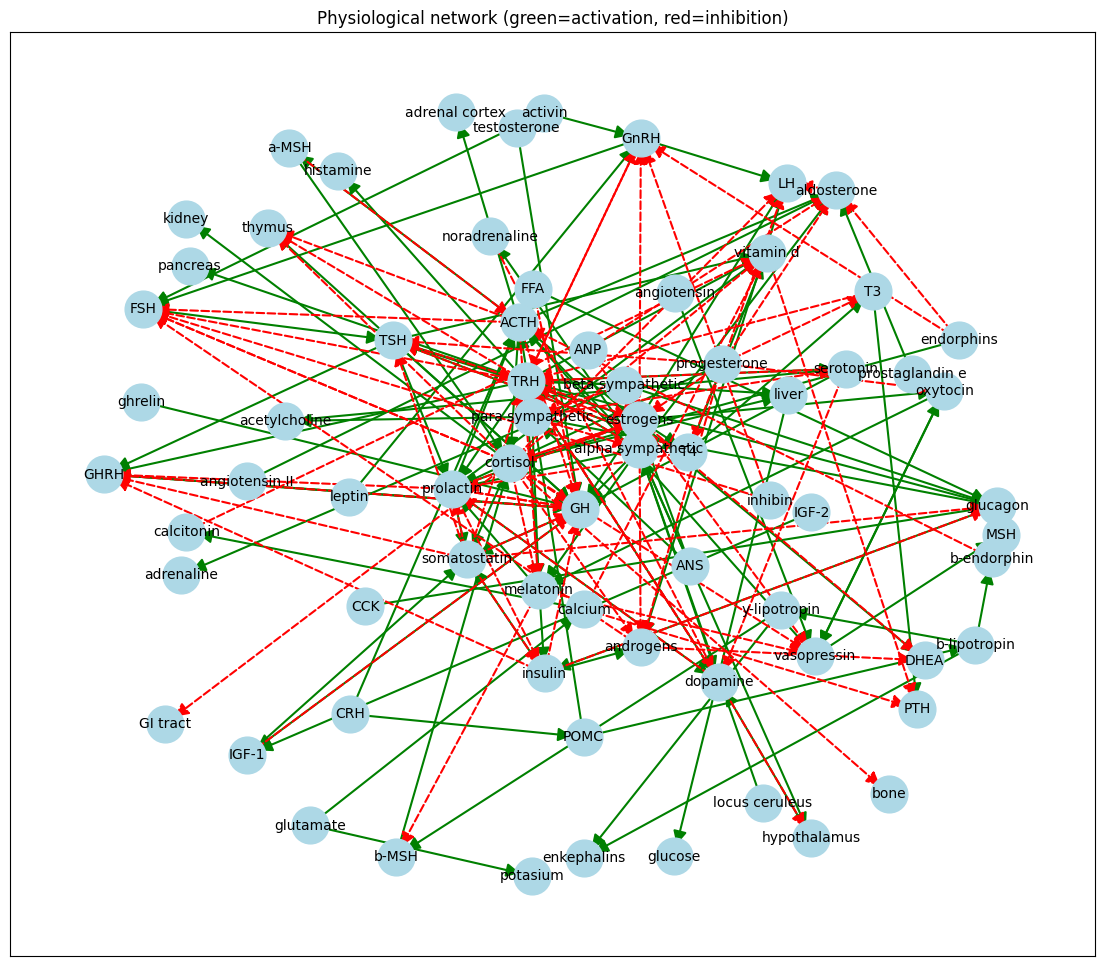

In [11]:
# To separeted the edges based on sign
positive_edges = [edge for edge in edge_list if edge[2]['sign'] == 1]
negative_edges = [edge for edge in edge_list if edge[2]['sign'] == -1]

# Plot the graph
plt.figure(figsize=(14, 12))
pos = nx.spring_layout(G, k=0.9, iterations=50)
nx.draw_networkx_nodes(G, pos, node_size=700, node_color='lightblue')
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edges(G, pos, edgelist=positive_edges, width=1.5, edge_color='green', arrowsize=20) #stimulation edges in green
nx.draw_networkx_edges(G, pos, edgelist=negative_edges, width=1.5, edge_color='red', arrowsize=20, style='dashed') #inhibition edges in red

plt.title("Physiological network (green=stimulation, red=inhibition)")
plt.show()

#### Metrics

##### Degree distribution

In [12]:
def plot_degree_distribution(G):
    degree_sequence = [d for n, d in G.degree()]
    plt.hist(degree_sequence, histtype = 'step')
    plt.xlabel('Degree $k$')
    plt.ylabel('$P(k)$')
    plt.title('Degree distribution')


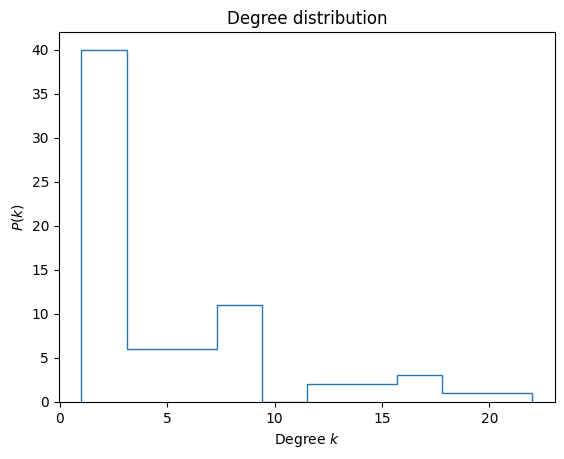

In [13]:
plot_degree_distribution(G)

##### Centrality measures

In [14]:
# Centrality
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

# To show the top 5 nodes (in & out)
top_5_in_degree = sorted(in_degree.items(), key=lambda item: item[1], reverse=True)[:5]
top_5_out_degree = sorted(out_degree.items(), key=lambda item: item[1], reverse=True)[:5]

print("Top 5 nodes (in-degree):")
print(top_5_in_degree)
print("\nTop 5 nodes (out-degree):")
print(top_5_out_degree)

Top 5 nodes (in-degree):
[('GH', 14), ('TRH', 10), ('prolactin', 9), ('ACTH', 7), ('aldosterone', 7)]

Top 5 nodes (out-degree):
[('cortisol', 14), ('TRH', 12), ('alpha sympathetic', 11), ('estrogens', 10), ('ACTH', 9)]


In [15]:
#  Betweenness Centrality
betweenness = nx.betweenness_centrality(G)
top_5_betweenness = sorted(betweenness.items(), key=lambda item: item[1], reverse=True)[:5]

print("\nTop 5 nodes (Betweenness):")
print(top_5_betweenness)


Top 5 nodes (Betweenness):
[('TRH', 0.1374537702404906), ('ACTH', 0.10344112292804447), ('cortisol', 0.09508671074063431), ('prolactin', 0.08493740219092331), ('somatostatin', 0.0771495640509725)]


##### Community analysis

In [16]:
import community as community_louvain #We import the algorithm algorithm

# For communities detection
partition = community_louvain.best_partition(G.to_undirected()) #Convert to an undirected network becasuse of algorithm

# To print the communities
print("\nCommunities detected:")
# To see the nodes that belong to each community
communities = {}
for node, comm_id in partition.items():
    if comm_id not in communities:
        communities[comm_id] = []
    communities[comm_id].append(node)

for comm_id, nodes in communities.items():
    print(f"Community {comm_id}: {nodes}")



Communities detected:
Community 0: ['alpha sympathetic', 'beta sympathetic', 'para sympathetic', 'ANS', 'noradrenaline', 'dopamine', 'acetylcholine', 'serotonin', 'adrenaline', 'hypothalamus', 'locus ceruleus']
Community 1: ['TRH', 'histamine', 'TSH', 'T4', 'pancreas', 'GH', 'GHRH', 'prolactin', 'insulin', 'T3', 'somatostatin', 'IGF-1', 'ghrelin', 'testosterone', 'FFA', 'IGF-2', 'glucagon', 'CCK']
Community 3: ['ACTH', 'CRH', 'adrenal cortex', 'liver', 'glucose', 'b-endorphin', 'cortisol', 'a-MSH', 'b-MSH', 'GI tract', 'bone', 'kidney', 'melatonin', 'POMC', 'b-lipotropin', 'enkephalins', 'y-lipotropin', 'vasopressin', 'angiotensin', 'ANP', 'MSH', 'thymus']
Community 4: ['FSH', 'GnRH', 'LH', 'activin', 'leptin', 'endorphins', 'inhibin', 'estrogens', 'androgens', 'aldosterone', 'progesterone', 'oxytocin', 'DHEA', 'prostaglandin e', 'angiotensin II']
Community 2: ['glutamate', 'calcium', 'potasium', 'calcitonin', 'vitamin d', 'PTH']


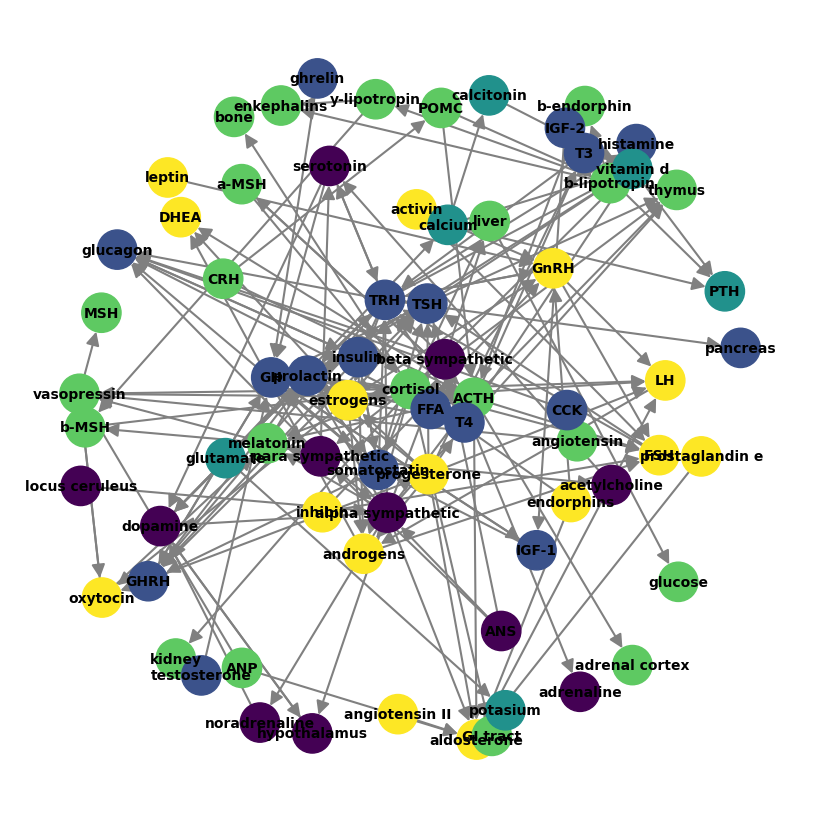

In [18]:
# Visualization
plt.figure(figsize=(8, 8)) #
pos = nx.spring_layout(G, k=0.9, iterations=50)
node_colors = [partition[node] for node in G.nodes()]

nx.draw(G, pos, with_labels=True, node_size=800, node_color=node_colors,
        font_size=10, font_weight='bold', width=1.5, arrowsize=20,
        edge_color='gray', cmap=plt.cm.viridis)
plt.show()